# MSIN0143 Programming for Business Analytics

## **RQ:** Which factors (road, time, weather and lighting conditions) are most associated with/affect the severity of a collision?

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from google.colab import drive
drive.mount('/content/drive')

FOLDER = '/content/drive/MyDrive/Masters/MSIN0143 Programming for Business Analytics Group Coursework/data/'
DATA_PATH = FOLDER + 'dft-road-casualty-statistics-collision-2025.csv'
DICT_PATH = FOLDER + 'dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx'

Mounted at /content/drive


In [5]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
df = raw.copy()

dictionary = pd.read_excel(DICT_PATH, sheet_name='2024_code_list')
dictionary = dictionary[dictionary['table'] == 'collision']

In [6]:
df.dtypes

,0
collision_index,object
collision_year,int64
collision_ref_no,object
location_easting_osgr,float64
location_northing_osgr,float64
longitude,float64
latitude,float64
police_force,int64
collision_severity,int64
number_of_vehicles,int64


# Data Cleaning

The dataset contains 101,525 collisions recorded by police in Great Britain in 2025, with 44 attributes. This analysis keeps 21 columns relevant to the research question: collision severity, and road, time, weather and lighting conditions. All other columns are dropped. STATS19 records every attribute as a numeric code, so the data guide (Department for Transport, 2025) is used throughout cleaning to interpret values.

In [7]:
# Selecting columns
analysis_cols = [
    'collision_ref_no', 'collision_severity', 'number_of_vehicles', 'number_of_casualties',
    'date', 'day_of_week', 'time', 'local_authority_ons_district', 'first_road_class', 'road_type',
    'speed_limit', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing',
    'light_conditions', 'weather_conditions', 'road_surface_conditions',
    'special_conditions_at_site', 'carriageway_hazards', 'urban_or_rural_area'
]

# Keep columns only used for this analysis
df = df[analysis_cols].copy()
print(f"Original: {raw.shape}, Analysis: {df.shape}")

df.head()

Original: (101525, 44), Analysis: (101525, 21)


,collision_ref_no,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_ons_district,first_road_class,road_type,...,junction_detail,junction_control,second_road_class,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area
0,17M101925,3,1,1,04/02/2025,3,15:00,E06000002,4,6,...,0,-1,0,13,1,1,1,-1,0,1
1,17L205225,3,2,1,07/05/2025,4,09:35,E06000003,5,6,...,0,-1,0,0,1,1,1,-1,0,1
2,070971700,3,2,2,27/11/2025,5,18:18,E06000006,6,6,...,13,2,6,15,4,1,2,-1,0,2
3,070403274,3,2,1,15/05/2025,5,16:30,E06000007,5,6,...,0,-1,0,0,1,1,1,-1,0,2
4,071000604,3,7,1,08/12/2025,2,07:45,E06000007,1,3,...,0,-1,0,-1,4,1,2,-1,0,2


In [8]:
# Check for duplicate rows and collision references
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df['collision_ref_no'].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0


In [9]:
# Replacing "unknown" values with missing values NaN
unknown_value = {
    'road_type': [9],
    'speed_limit': [99],
    'junction_detail': [99],
    'junction_control': [9],
    'second_road_class': [9],
    'pedestrian_crossing': [99],
    'weather_conditions': [9],
    'road_surface_conditions': [9],
    'special_conditions_at_site': [9],
    'carriageway_hazards': [99],
    'urban_or_rural_area': [3]
}

df = df.replace(-1, np.nan)
df = df.replace(unknown_value, np.nan)

# % missing per column after recoding
df.isna().mean().mul(100).round(1).sort_values()

,0
collision_ref_no,0.0
collision_severity,0.0
number_of_vehicles,0.0
number_of_casualties,0.0
date,0.0
day_of_week,0.0
time,0.0
local_authority_ons_district,0.0
first_road_class,0.0
speed_limit,0.0


In [10]:
# Fix structural missing values

# Junction control does not apply when there is no junction, so recode as 'not at junction'
df.loc[(df['junction_detail'] == 0) & df['junction_control'].isna(), 'junction_control'] = 0

# Drop a mostly empty column that has been replaced by carriageway_hazards
df = df.drop(columns=['special_conditions_at_site'], errors='ignore')

In [11]:
# Missing value report
# Compare the severity of rows with missing values against all collisions

fatal = df['collision_severity'] == 1     # 1 = Fatal
serious = df['collision_severity'] == 2   # 2 = Serious

missing = df.isna()

print(f"Overall: {fatal.mean():.1%} fatal, {serious.mean():.1%} serious")

report = pd.DataFrame({
    'missing_%': missing.mean() * 100,
    'fatal_%_if_missing': [fatal[missing[c]].mean() * 100 for c in df.columns],
    'serious_%_if_missing': [serious[missing[c]].mean() * 100 for c in df.columns],
}).round(2)
report[missing.any()].sort_values('missing_%', ascending=False)

Overall: 1.4% fatal, 24.8% serious


,missing_%,fatal_%_if_missing,serious_%_if_missing
junction_detail,8.01,0.54,17.08
pedestrian_crossing,6.73,0.03,10.69
carriageway_hazards,5.95,0.02,10.86
junction_control,4.47,0.31,10.84
weather_conditions,2.35,0.13,12.33
road_surface_conditions,1.95,0.10,9.41
road_type,1.92,0.00,10.70
second_road_class,0.22,2.28,11.87
light_conditions,0.02,0.00,25.00
first_road_class,0.01,0.00,0.00


In [12]:
# Handle remaining missing values
# Drop rows where few values are missing; label the rest 'Unknown' (next cell)

drop_rows = ['first_road_class', 'road_type', 'second_road_class', 'light_conditions',
               'weather_conditions', 'road_surface_conditions', 'urban_or_rural_area']
unknown_cat = ['junction_detail', 'junction_control', 'pedestrian_crossing', 'carriageway_hazards']

before = len(df)
df = df.dropna(subset=drop_rows)
print(f"Removed {before - len(df):,} rows ({(before - len(df)) / before:.1%}), {len(df):,} remain")

Removed 4,573 rows (4.5%), 96,952 remain


In [13]:
# Replace codes with labels from the DfT data guide
# Derive nation from the district code before the codes are replaced
df['nation'] = df['local_authority_ons_district'].str[0].map(
    {'E': 'England', 'W': 'Wales', 'S': 'Scotland'})

coded_cols = ['collision_severity', 'day_of_week', 'local_authority_ons_district', 'first_road_class',
              'road_type', 'junction_detail', 'junction_control', 'second_road_class',
              'pedestrian_crossing', 'light_conditions', 'weather_conditions',
              'road_surface_conditions', 'carriageway_hazards', 'urban_or_rural_area']

for col in coded_cols:
    rows = dictionary[dictionary['field name'] == col]
    keys = rows['code/format'] if col == 'local_authority_ons_district' else pd.to_numeric(rows['code/format'], errors='coerce')
    mapping = dict(zip(keys, rows['label'].fillna('None present')))   # fill blank labels
    if col == 'local_authority_ons_district':
        # Add codes missing from the guide
        mapping.update({'E08000038': 'Barnsley', 'E08000039': 'Sheffield'})
    df[col] = df[col].map(mapping)

df[unknown_cat] = df[unknown_cat].fillna('Unknown')
df['speed_limit'] = df['speed_limit'].astype(int)   # keep as a number
df.head()

,collision_ref_no,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_ons_district,first_road_class,road_type,...,junction_detail,junction_control,second_road_class,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,carriageway_hazards,urban_or_rural_area,nation
0,17M101925,Slight,1,1,04/02/2025,Tuesday,15:00,Middlesbrough,B,Single carriageway,...,Not at junction or within 20 metres,Not at junction or within 20 metres,Not at junction or within 20 metres,Zebra crossing,Daylight,Fine no high winds,Dry,None present,Urban,England
1,17L205225,Slight,2,1,07/05/2025,Wednesday,09:35,Redcar and Cleveland,C,Single carriageway,...,Not at junction or within 20 metres,Not at junction or within 20 metres,Not at junction or within 20 metres,No physical crossing facility within 50m,Daylight,Fine no high winds,Dry,None present,Urban,England
2,070971700,Slight,2,2,27/11/2025,Thursday,18:18,Halton,Unclassified,Single carriageway,...,T or staggered junction,Auto traffic signal,Unclassified,Pedestrian phase at traffic signal,Darkness - lights lit,Fine no high winds,Wet or damp,None present,Rural,England
3,070403274,Slight,2,1,15/05/2025,Thursday,16:30,Warrington,C,Single carriageway,...,Not at junction or within 20 metres,Not at junction or within 20 metres,Not at junction or within 20 metres,No physical crossing facility within 50m,Daylight,Fine no high winds,Dry,None present,Rural,England
4,071000604,Slight,7,1,08/12/2025,Monday,07:45,Warrington,Motorway,Dual carriageway,...,Not at junction or within 20 metres,Not at junction or within 20 metres,Not at junction or within 20 metres,Unknown,Darkness - lights lit,Fine no high winds,Wet or damp,None present,Rural,England


In [14]:
# Outlier check and final checks
# Check count variables for extreme values
print(df[['number_of_vehicles', 'number_of_casualties']].describe().round(2))

# Set severity as an ordered category
df['collision_severity'] = pd.Categorical(df['collision_severity'],
                                          categories=['Slight', 'Serious', 'Fatal'], ordered=True)
print(df['collision_severity'].value_counts(normalize=True).mul(100).round(1))

assert df.isna().sum().sum() == 0, "Missing values remain"
print(df.shape)

       number_of_vehicles  number_of_casualties
count            96952.00              96952.00
mean                 1.82                  1.27
std                  0.70                  0.83
min                  1.00                  1.00
25%                  1.00                  1.00
50%                  2.00                  1.00
75%                  2.00                  1.00
max                 17.00                142.00
collision_severity
Slight     73.1
Serious    25.4
Fatal       1.5
Name: proportion, dtype: float64
(96952, 21)


**1. Small counts in the missing value report.** Some columns have only a handful of missing rows: light conditions (16), first road class (6) and urban/rural area (4). Their fatal and serious percentages are therefore unreliable (e.g. "50% serious" is based on 4 collisions) and are not interpreted.

**2. Inconsistent junction fields.** second_road_class records the class of the second road at a junction. However, around 19,800 collisions recorded a second road class despite junction_detail stating "not at junction". Since junction_detail is the primary junction field in the 2024 STATS19 specification, it is treated as the more reliable of the two.

# Exploratory Data Analysis

## Target variable: Collission Severity

In [18]:
severity = df['collision_severity']

severity_summary = pd.DataFrame({
    'count': severity.value_counts().sort_index(),
    'percent': severity.value_counts(normalize=True).mul(100).round(1)
}).reindex(['Fatal', 'Serious', 'Slight'])

severity_summary

,count,percent
collision_severity,,
Fatal,1444,1.5
Serious,24624,25.4
Slight,70884,73.1


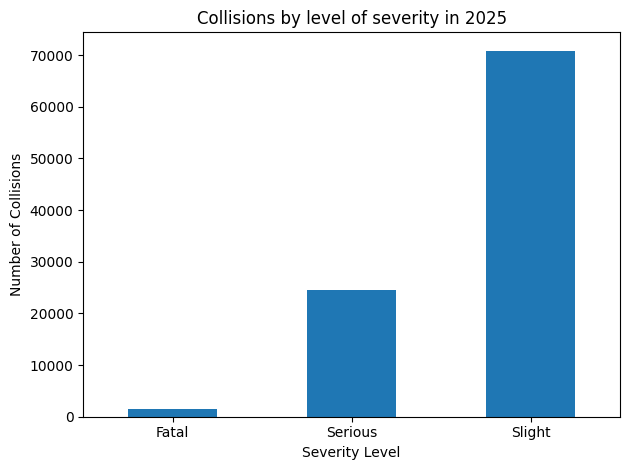

In [19]:
ax = severity_summary['count'].plot(kind='bar')
ax.set_title('Collisions by level of severity in 2025')
ax.set_xlabel('Severity Level')
ax.set_ylabel('Number of Collisions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Missing values before and after cleaning

## Distribution of Explanatory Variables

### Numeric Variables

### Categorical Variables

### Monthly trend in Collisions

### Collisions by location (Top 10 local authorities)

## Explanatory variables and Collision Severity

### Road Factors
* Speed limit
* Road type
* Road class
* Junction detail
* Junction control

### Environmental Factors
* Light conditions
* Weather conditions
* Road surface conditions

### Time Factors
* Hour of day
* Day of week
* Month

### Urban vs Rural area

### Carriageway Hazards

## Summary of EDA Findings